<a href="https://colab.research.google.com/github/hilalozkaraman/PoseCoach/blob/main/PoseCoach_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PoseCoach — Temiz Video Veri Seti ile Çoklu Yoga Hareket Analizi

**Bilgisayarla Görü / Problem 1 — Google Colab sürümü**

Bu defter, **düzenlediğin yalnızca-videolar veri setini** kullanır. Aynı yoga hareketine ve aynı kamera açısına ait `Right` / `Wrong` videolarını otomatik eşleştirir. `Right` videodaki eklem açısı zaman serisi, `Wrong` için **harekete özel referans** görevi görür. Dynamic Time Warping (DTW) farklı hızları eşleştirmek için kullanılır. Eklem farkları derece olarak ölçülür ve Türkçe düzeltici geri bildirim hazırlanır.

**Önemli sınırlılıklar:** Eklem açıları MediaPipe 3B world landmarklarıyla, gövde eğimi/omuz hizası/bilek yüksekliği/ayak açıklığı ise görüntü düzleminde (2B) hesaplanır; kişinin boyu, görüş açısı ve örtülme hataya neden olabilir. DTW yinelenen hareketleri kısmen gizleyebilir. Bu nedenle ölçüm sonuçları otomatik **klinik doğruluk** veya otomatik **etiket doğrulaması** değildir. `Wrong` etiketi, ölçüme girdi olarak kullanılmaz; yalnızca hangi videonun referansla kıyaslanacağını seçer.

**Çalıştırma düzeni:** 1) Drive'a bağlan → 2) katalog ve eşleşmeleri kontrol et → 3) tek çiftte örnek dene → 4) istediğinde bütün eşleşmeleri çalıştır. Kod arşivin ZIP ya da klasör olarak saklanmasını destekler.
Bu sürümün sentetik testleri video performansı anlamına gelmez.


## 1 — Kurulum ve kütüphaneler
İlk çalıştırmada MediaPipe pose modeli indirilecektir. Google Colab CPU çalışma zamanı yeterlidir.

In [1]:
%pip -q install "mediapipe>=0.10.20,<0.11" "pandas>=2,<3" "matplotlib>=3.7,<4" "scipy>=1.10"

In [2]:
from google.colab import drive
from IPython.display import display
from pathlib import Path
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
import mediapipe as mp
from scipy.spatial.distance import cdist
import os, re, zipfile, shutil, hashlib, urllib.request, unicodedata, json, sys, warnings

print('Python:', sys.version.split()[0], '| MediaPipe:', mp.__version__, '| OpenCV:', cv2.__version__)
MODEL_YOLU = Path('/content/pose_landmarker_full.task')
MODEL_URL = ('https://storage.googleapis.com/mediapipe-models/pose_landmarker/'
             'pose_landmarker_full/float16/1/pose_landmarker_full.task')
if not MODEL_YOLU.exists() or MODEL_YOLU.stat().st_size < 1_000_000:
    urllib.request.urlretrieve(MODEL_URL, MODEL_YOLU)
print('Model hazır:', MODEL_YOLU)

Python: 3.13.16 | MediaPipe: 0.10.35 | OpenCV: 4.14.0
Model hazır: /content/pose_landmarker_full.task


## 2 — Drive konumu


In [3]:
drive.mount('/content/drive')
# Kendi Drive klasörünün adına göre sadece bu satırı değiştirmen yeterli.
VERI_YOLU = Path('/content/drive/MyDrive/PoseCoach_Veriler')
SONUC_TABAN = Path('/content/drive/MyDrive/PoseCoach_CokluHareket_Sonuclar')
SONUC_TABAN.mkdir(parents=True, exist_ok=True)
# Her çalıştırma KENDİ klasörüne yazılır; eski sonuçlar üzerine yazılmaz. Yeni deneme için RUN_ADI'nı değiştir.
RUN_ADI = 'v10_4'
SONUC_YOLU = SONUC_TABAN / RUN_ADI
SONUC_YOLU.mkdir(parents=True, exist_ok=True)
GECICI_YOL = Path('/content/posecoach_video_cache')
GECICI_YOL.mkdir(parents=True, exist_ok=True)
OZELLIK_ONBELLEK = SONUC_TABAN / 'ozellik_onbellegi'   # ortak: video analizleri tekrarlanmaz (özellik tanımı değişirse bu klasörü sil)
OZELLIK_ONBELLEK.mkdir(exist_ok=True)

if not VERI_YOLU.exists():
    print('MyDrive içindeki klasörler:', [p.name for p in Path('/content/drive/MyDrive').iterdir() if p.is_dir()][:35])
    raise FileNotFoundError(f'Drive veri yolu bulunamadı: {VERI_YOLU}. Yukarıdaki VERI_YOLU değerini düzelt.')
print('Kaynak:', VERI_YOLU)
print('Sonuç:', SONUC_YOLU)

Mounted at /content/drive
Kaynak: /content/drive/MyDrive/PoseCoach_Veriler
Sonuç: /content/drive/MyDrive/PoseCoach_CokluHareket_Sonuclar/v10_4


## 3 — Video kataloglama ve eşleştirme
Bütün `.mp4/.mov/.avi/.mkv` dosyaları bulunur. `Right` / `Wrong` ve `Angle 1–4` bilgileri dosya ve klasör adlarından okunur. Düzenlediğin etiketler doğrudan esas alınır. Eksik, çift kayıtlı veya okunamayan eşleşmeler sessizce karıştırılmaz.

In [4]:
VIDEO_UZANTILARI = {'.mp4', '.mov', '.avi', '.mkv', '.m4v', '.webm'}
BILINEN_POZLAR = [
    'Tadasana', 'Anantasana', 'Ardhakati Chakrasana', 'Bhujangasana',
    'Kati Chakrasana', 'Marjariasana', 'Parvatasana', 'Sarvangasana',
    'Vajrasana', 'Viparita Karani'
]

def norm(s):
    s = unicodedata.normalize('NFKD', str(s)).casefold()
    return ''.join(c for c in s if not unicodedata.combining(c))

def meta_ayikla(yol):
    yol = str(yol).replace('\\', '/')
    parcali = yol.split('/')
    tam = norm(yol)
    pose = next((p for p in BILINEN_POZLAR if norm(p) in tam), None)
    if pose is None:
        # Genel şema: <hareket>/Right/Angle_1.mp4 veya <hareket>/<hareket Wrong Steps>/...mp4
        indeks = next((i for i,p in enumerate(parcali) if re.search(r'(^|[^a-z])(right|wrong|correct|incorrect)([^a-z]|$)', norm(p))), None)
        if indeks is not None and indeks > 0:
            onceki = parcali[indeks-1]
            if norm(onceki) not in ('videos','video','dataset',''): pose = onceki
        if pose is None:
            mat = re.search(r'(.+?)\s+(?:right|wrong)\s+steps?', Path(yol).stem, flags=re.I)
            if mat: pose = mat.group(1).strip()
    isim_bolumleri = [norm(p) for p in parcali]
    eslesen = []
    for parca in isim_bolumleri:
        m = re.search(r'(^|[^a-z])(right|wrong|correct|incorrect)([^a-z]|$)', parca)
        if m: eslesen.append(m.group(2))
    etiket = {'right':'Right','correct':'Right','wrong':'Wrong','incorrect':'Wrong'}.get(eslesen[-1], None) if eslesen else None
    aci = None
    for parca in reversed(isim_bolumleri):
        m = re.search(r'(?:angle|aci|camera|view)[^0-9]{0,7}([1-4])(?:[^0-9]|$)', parca)
        if m: aci = int(m.group(1)); break
    return pose, etiket, aci


def katalog_olustur(kaynak):
    satirlar = []
    adaylar = [kaynak] if kaynak.is_file() else list(kaynak.rglob('*'))
    for p in adaylar:
        if not p.is_file(): continue
        if p.suffix.lower() in VIDEO_UZANTILARI:
            pose, etiket, aci = meta_ayikla(str(p))
            satirlar.append(dict(poz=pose, etiket=etiket, aci=aci,
                                 tip='video', kaynak=str(p), zip_uyesi='',
                                 boyut_mb=round(p.stat().st_size/1024**2, 2)))
        elif p.suffix.lower()=='.zip':
            with zipfile.ZipFile(p) as z:
                for info in z.infolist():
                    if info.is_dir() or Path(info.filename).suffix.lower() not in VIDEO_UZANTILARI: continue
                    pose, etiket, aci = meta_ayikla(info.filename)
                    satirlar.append(dict(poz=pose, etiket=etiket, aci=aci,
                                         tip='zip', kaynak=str(p), zip_uyesi=info.filename,
                                         boyut_mb=round(info.file_size/1024**2, 2)))
    df = pd.DataFrame(satirlar, columns=['poz','etiket','aci','tip','kaynak','zip_uyesi','boyut_mb'])
    return df

KATALOG = katalog_olustur(VERI_YOLU)
if KATALOG.empty: raise RuntimeError('Video dosyası bulunamadı. VERI_YOLU ve ZIP içeriğini kontrol et.')
KATALOG.insert(0, 'video_id', np.arange(len(KATALOG)))
KATALOG.to_csv(SONUC_YOLU/'video_katalogu.csv', index=False, encoding='utf-8-sig')
print(f'Video sayısı: {len(KATALOG)} | Hareket sayısı: {KATALOG.poz.nunique()}')
print('Etiket dağılımı:', KATALOG.etiket.value_counts(dropna=False).to_dict())
print('Kamera açısı dağılımı:', KATALOG.aci.value_counts(dropna=False).to_dict())
if KATALOG[['poz','etiket','aci']].isna().any(axis=1).any():
    print('UYARI: Etiketi tanınamayan dosyalar mevcut:')
    display(KATALOG[KATALOG[['poz','etiket','aci']].isna().any(axis=1)])
display(KATALOG[['poz','etiket','aci','boyut_mb']].groupby(['poz','etiket','aci'],dropna=False).size().reset_index(name='video_sayisi').head(80))

Video sayısı: 80 | Hareket sayısı: 10
Etiket dağılımı: {'Right': 40, 'Wrong': 40}
Kamera açısı dağılımı: {1: 20, 2: 20, 3: 20, 4: 20}


,poz,etiket,aci,video_sayisi
0,Anantasana,Right,1,1
1,Anantasana,Right,2,1
2,Anantasana,Right,3,1
3,Anantasana,Right,4,1
4,Anantasana,Wrong,1,1
...,...,...,...,...
75,Viparita Karani,Right,4,1
76,Viparita Karani,Wrong,1,1
77,Viparita Karani,Wrong,2,1
78,Viparita Karani,Wrong,3,1


In [5]:
def ciftleri_kur(katalog):
    rows, sorunlar = [], []
    uygun = katalog.dropna(subset=['poz','etiket','aci'])
    for (pose,aci), g in uygun.groupby(['poz','aci'],sort=True):
        r=g[g.etiket=='Right']; w=g[g.etiket=='Wrong']
        if len(r)==1 and len(w)==1:
            rows.append(dict(poz=pose, aci=int(aci), right_id=int(r.iloc[0].video_id), wrong_id=int(w.iloc[0].video_id)))
        else:
            sorunlar.append(dict(poz=pose, aci=int(aci), right_adet=len(r), wrong_adet=len(w)))
    return pd.DataFrame(rows,columns=['poz','aci','right_id','wrong_id']), pd.DataFrame(sorunlar)

CIFTLER, SORUNLAR = ciftleri_kur(KATALOG)
CIFTLER.to_csv(SONUC_YOLU/'video_ciftleri.csv',index=False,encoding='utf-8-sig')
print('Eksiksiz eşleşen Right/Wrong çiftleri:',len(CIFTLER))
if not SORUNLAR.empty:
    print('Dikkat: Eksik veya mükerrer eşleşmeler:')
    display(SORUNLAR)
if CIFTLER.empty: raise RuntimeError('Eşleşen video çifti bulunamadı; dosya/klasör adlarında Right/Wrong ve Angle 1..4 aranıyor.')
display(CIFTLER)

Eksiksiz eşleşen Right/Wrong çiftleri: 40


,poz,aci,right_id,wrong_id
0,Anantasana,1,0,4
1,Anantasana,2,1,5
2,Anantasana,3,2,6
3,Anantasana,4,3,7
4,Ardhakati Chakrasana,1,8,12
5,Ardhakati Chakrasana,2,9,13
6,Ardhakati Chakrasana,3,10,14
7,Ardhakati Chakrasana,4,11,15
8,Bhujangasana,1,16,20
9,Bhujangasana,2,17,21


## 4 — Video hazırlama ve analiz ayarları
Varsayılan olarak saniyede 2 kare örneklenir. **80 video analizinin işlem süresi uzun olabilir.** Daha iyi ölçüm için `ORNEK_FPS=4` yapılabilir. Çalıştırma kesilirse hesaplanan videolar önbellekte kalır.

In [6]:
ORNEK_FPS = 2
MAKS_SURE_S = 120
MAKS_GENISLIK = 640
GORUNURLUK_ESIGI = 0.55
ACI_3B = True   # True: eklem açıları MediaPipe world (3B, metre) landmarklarıyla hesaplanır; kameraya doğru uzanan uzuvlardaki perspektif kısalmasını azaltır
CACHE_SURUMU = 'v4_3b_karismaz'   # özellik tanımı değişince artır (eski önbellek kullanılmaz)

ACILAR = {
    'Sağ dirsek':(12,14,16), 'Sol dirsek':(11,13,15),
    'Sağ omuz':(14,12,24), 'Sol omuz':(13,11,23),
    'Sağ kalça':(12,24,26), 'Sol kalça':(11,23,25),
    'Sağ diz':(24,26,28), 'Sol diz':(23,25,27),
    'Sağ ayak bileği':(26,28,32), 'Sol ayak bileği':(25,27,31),   # diz-bilek-ayak ucu
}
TOLERANS = {
    **{k:15.0 for k in ACILAR if 'dirsek' in k or 'diz' in k},
    **{k:20.0 for k in ACILAR if 'omuz' in k or 'kalça' in k or 'ayak bileği' in k},
    'Gövde eğimi':12.0, 'Omuz hizası':10.0,
    'Sağ bilek yüksekliği (oran)':0.45,
    'Sol bilek yüksekliği (oran)':0.45,
    'Ayak açıklığı (oran)':0.40,
}
FEATURES = list(TOLERANS)

def uc_nokta_acisi(a,b,c):
    a,b,c=[np.asarray(x,float) for x in (a,b,c)]
    u,v=a-b,c-b
    payda=np.linalg.norm(u)*np.linalg.norm(v)
    if payda < 1e-9: return np.nan
    return float(np.degrees(np.arccos(np.clip(np.dot(u,v)/payda,-1,1))))

def kare_ozellikleri(landmarks,width,height,dunya=None):
    sonuc={k:np.nan for k in FEATURES}
    if landmarks is None or len(landmarks)!=33: return sonuc
    def p(i):
        x,y,visibility=landmarks[i]
        if not np.isfinite([x,y,visibility]).all() or visibility < GORUNURLUK_ESIGI: return None
        return np.array([x*width, y*height])
    for ad,(a,b,c) in ACILAR.items():
        q=[p(a),p(b),p(c)]
        if all(x is not None for x in q):          # görünürlük kapısı 2B landmarklardan
            if not ACI_3B:
                sonuc[ad]=uc_nokta_acisi(*q)                              # yalnızca 2B modu
            elif dunya is not None and np.isfinite(dunya[[a,b,c]]).all():
                sonuc[ad]=uc_nokta_acisi(dunya[a],dunya[b],dunya[c])     # 3B açı
            # 3B modunda world landmark yoksa NaN kalır: aynı sütunda 2B ve 3B ölçümler KARIŞTIRILMAZ
    lsh,rsh,lh,rh=p(11),p(12),p(23),p(24)
    if all(x is not None for x in (lsh,rsh,lh,rh)):
        s=(lsh+rsh)/2; h=(lh+rh)/2; v=h-s
        if np.linalg.norm(v)>1: sonuc['Gövde eğimi']=float(np.degrees(np.arctan2(-v[0],abs(v[1]))))   # + : omuzlar kalçaya göre GÖRÜNTÜDE sağda
        v=rsh-lsh
        if np.linalg.norm(v)>1: sonuc['Omuz hizası']=float(np.degrees(np.arctan2(abs(v[1]),abs(v[0]))))
    for yan,si,wi,hi in [('Sağ',12,16,24),('Sol',11,15,23)]:
        sh,wr,hip=p(si),p(wi),p(hi)
        if all(x is not None for x in (sh,wr,hip)):
            torso=np.linalg.norm(hip-sh)
            if torso > max(8,height*0.07):
                sonuc[f'{yan} bilek yüksekliği (oran)']=float((sh[1]-wr[1])/torso)
    la,ra=p(27),p(28)
    if all(x is not None for x in (lsh,rsh,la,ra)):
        sw=np.linalg.norm(lsh-rsh)
        if sw > max(15,width*0.045):
            sonuc['Ayak açıklığı (oran)']=float(np.linalg.norm(la-ra)/sw)
    return sonuc

assert abs(uc_nokta_acisi([1,0],[0,0],[0,1])-90)<1e-6
assert abs(uc_nokta_acisi([-1,0],[0,0],[1,0])-180)<1e-6
_lm=np.zeros((33,3)); _lm[:,2]=1
_lm[11]=[.55,.3,1]; _lm[12]=[.65,.3,1]; _lm[23]=[.45,.6,1]; _lm[24]=[.55,.6,1]
assert 15 < kare_ozellikleri(_lm,100,100)['Gövde eğimi'] < 22      # omuzlar kalçanın sağında -> pozitif ~18°
assert abs(uc_nokta_acisi([1,0,0],[0,0,0],[0,0,1])-90)<1e-6
# Kameraya doğru düz uzanan kol: 2B'de kısalır (küçük açı), 3B'de ~180° olmalı
_lm=np.zeros((33,3)); _lm[:,2]=1; _lm[12]=[.5,.40,1]; _lm[14]=[.5,.45,1]; _lm[16]=[.5,.42,1]
_dw=np.zeros((33,3)); _dw[12]=[0,0,0]; _dw[14]=[0,0,-.3]; _dw[16]=[0,0,-.6]
assert np.isnan(kare_ozellikleri(_lm,100,100)['Sağ dirsek'])             # 3B modunda world yoksa 2B'ye düşülmez
assert kare_ozellikleri(_lm,100,100,_dw)['Sağ dirsek'] > 170
_a3=ACI_3B; ACI_3B=False
assert kare_ozellikleri(_lm,100,100)['Sağ dirsek'] < 30                   # 2B modunda kısalma görülür (3B'nin neden gerekli olduğu)
ACI_3B=_a3
print('Geometrik ölçüm testleri başarılı.')

Geometrik ölçüm testleri başarılı.


In [7]:
def video_hazirla(kayit):
    kaynak = Path(kayit['kaynak'])
    vid = hashlib.sha1((str(kaynak)+'|'+str(kayit['zip_uyesi'])).encode()).hexdigest()[:15]
    hedef = GECICI_YOL / f'{vid}{Path(kayit["zip_uyesi"] or kaynak.name).suffix.lower()}'
    if hedef.exists() and hedef.stat().st_size>0: return hedef
    if kayit['tip']=='zip':
        with zipfile.ZipFile(kaynak) as zf, zf.open(kayit['zip_uyesi']) as inp, open(hedef,'wb') as out:
            shutil.copyfileobj(inp,out)
    else:
        shutil.copyfile(kaynak,hedef)
    return hedef

def onbellek_anahtari(kayit):
    kaynak=Path(kayit['kaynak'])
    temel=f'{kayit["kaynak"]}|{kayit["zip_uyesi"]}|{kaynak.stat().st_mtime_ns}|{kaynak.stat().st_size}|{ORNEK_FPS}|{MAKS_SURE_S}|{MAKS_GENISLIK}|{GORUNURLUK_ESIGI}|{mp.__version__}|{CACHE_SURUMU}|{ACI_3B}'
    return hashlib.sha256(temel.encode('utf-8')).hexdigest()[:22]

def video_analiz_et(kayit):
    cache=OZELLIK_ONBELLEK/(onbellek_anahtari(kayit)+'.csv')
    if cache.exists(): return pd.read_csv(cache)
    gecici=video_hazirla(kayit)
    cap=cv2.VideoCapture(str(gecici))
    if not cap.isOpened(): raise RuntimeError(f'Video açılamadı: {gecici}')
    fps=float(cap.get(cv2.CAP_PROP_FPS))
    if fps<=0 or not np.isfinite(fps): fps=30.
    adim=max(1,int(round(fps/ORNEK_FPS)))
    satirlar=[]; frame_no=0; son_ms=-1
    opts=mp.tasks.vision.PoseLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(MODEL_YOLU)),
        running_mode=mp.tasks.vision.RunningMode.VIDEO, num_poses=1,
        min_pose_detection_confidence=0.5, min_pose_presence_confidence=0.5,
        min_tracking_confidence=0.5)
    try:
        with mp.tasks.vision.PoseLandmarker.create_from_options(opts) as det:
            while True:
                saniye=frame_no/fps
                if saniye>MAKS_SURE_S: break
                ok,bgr=cap.read()
                if not ok: break
                if frame_no%adim==0:
                    h,w=bgr.shape[:2]
                    if w>MAKS_GENISLIK:
                        scale=MAKS_GENISLIK/w
                        bgr=cv2.resize(bgr,(MAKS_GENISLIK,max(1,int(h*scale))))
                    h,w=bgr.shape[:2]
                    rgb=np.ascontiguousarray(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))
                    mpimg=mp.Image(image_format=mp.ImageFormat.SRGB,data=rgb)
                    ms=max(int(round(saniye*1000)),son_ms+1); son_ms=ms
                    detec=det.detect_for_video(mpimg,ms)
                    land=None; dunya=None
                    if detec.pose_landmarks:
                        land=np.array([[q.x,q.y,float(q.visibility if q.visibility is not None else 1.0)]
                                       for q in detec.pose_landmarks[0]],dtype=float)
                    wl=getattr(detec,'pose_world_landmarks',None)
                    if ACI_3B and wl:
                        dunya=np.array([[q.x,q.y,q.z] for q in wl[0]],dtype=float)
                    satirlar.append(dict(zaman_s=saniye, frame=frame_no, goruldu=int(land is not None),
                                         **kare_ozellikleri(land,w,h,dunya)))
                frame_no+=1
    finally:
        cap.release()
        # Geçici video kopyalarını büyütmemek için işlemden sonra kaldır.
        try: gecici.unlink(missing_ok=True)
        except OSError: pass
    if not satirlar: raise ValueError('Video kareleri okunamadı')
    df=pd.DataFrame(satirlar)
    df.to_csv(cache,index=False)
    return df

## 5 — Zamansal hizalama (DTW) ve hata karşılaştırması
Her eşleşme için Right ve Wrong dizilerindeki aynı hareket aşamaları DTW ile hizalanır. Geri bildirim, hizalanan karelerde ardışık tolerans aşımı gösteren **sapma segmentlerinden** (süre × büyüklük önceliğiyle) üretilir; kısa ama büyük hatalar (ör. kolun erken inmesi) kaybolmaz.

In [8]:
# Yandan çekilen açılarda (veride Açı 2 ve 4: omuz çizgisi ölçümü 50-70° çıkıyor) omuz hizası ve ayak açıklığı
# derinlik yüzünden anlamsızlaşır; bu açılarda hizalamaya ve geri bildirime katılmaz. (Açı numaralarını videolara bakıp doğrula.)
YAN_ACILAR = {2, 4}
YAN_ATLA = {'Omuz hizası', 'Ayak açıklığı (oran)'}
# Gövdenin DİK olduğu hareketler: yalnızca bunlarda "yukarı kaldır / sağa eğiyorsun / omurganı dik tut" gibi yön ifadeleri kullanılır.
# Yatarak, dört ayak üzerinde veya ters yapılan hareketlerde aynı ölçümler yönden bağımsız cümlelerle raporlanır. Gerekirse listeyi düzenle.
DIK_POZLAR = {'Tadasana', 'Ardhakati Chakrasana', 'Kati Chakrasana', 'Vajrasana'}

def dtw_yolu(ref_df,user_df,ihmal=()):
    # Her iki videoda yeterince görülebilen eklemler DTW için kullanılır.
    kullan=[k for k in FEATURES if k not in ihmal and ref_df[k].notna().mean()>=0.55 and user_df[k].notna().mean()>=0.55]
    if len(kullan)<2: raise ValueError('Yeterli ortak eklem ölçümü yok (en az iki özellik gerekli).')
    def hazirla(df):
        x=df[kullan].copy().interpolate(limit_direction='both')
        return x.fillna(x.median()).fillna(0).to_numpy(float) / np.array([TOLERANS[k] for k in kullan])[None,:]
    A=hazirla(ref_df); B=hazirla(user_df)
    D=cdist(A,B,metric='euclidean')
    n,m=D.shape
    dp=np.full((n+1,m+1),np.inf); dp[0,0]=0
    # Her adımda referans ve kullanıcı videosunun tam indekslerini izleyebiliriz.
    for i in range(1,n+1):
        for j in range(1,m+1):
            dp[i,j]=D[i-1,j-1]+min(dp[i-1,j],dp[i,j-1],dp[i-1,j-1])
    i,j=n,m; c=[]
    while i>0 and j>0:
        c.append((i-1,j-1))
        a=[dp[i-1,j-1],dp[i-1,j],dp[i,j-1]]
        sec=int(np.argmin(a))
        if sec==0: i-=1; j-=1
        elif sec==1: i-=1
        else: j-=1
    c.reverse()
    return np.array(c,dtype=int), float(dp[n,m]/max(len(c),1)), kullan

MIN_SEGMENT_KARE = 3   # ardışık en az bu kadar örnek (ORNEK_FPS=2 -> ~1.5 sn) tolerans dışıysa "sapma" say; tek-kare pose hatalarını eler

MIN_OLCUM_DOGRU = 8   # Olumlu geri bildirim için en az 8 ölçüm ve 3 olumlu ölçüm grubu; tekrar uyarısı olmamalı
MAX_OLAY_SURESI = 8.0   # saniye: zincirleme birleştirme bir olayı bu süreden uzun yapmaz (ardışık küçük sapmalar tek dev olaya dönüşmesin)
SIDDET_ESIGI = 1.5   # sapma, ortalama olarak toleransın en az bu katı ise raporlanır (sınırdaki küçük farklar yanlış alarm üretir)

def _segmentler(asim, min_kare):
    """Boolean dizide ardışık True bloklarını (baslangic, bitis) olarak döndürür."""
    out, i, n = [], 0, len(asim)
    while i < n:
        if asim[i]:
            j = i
            while j + 1 < n and asim[j + 1]: j += 1
            if j - i + 1 >= min_kare: out.append((i, j))
            i = j + 1
        else: i += 1
    return out

def _ref_karesi_tutarli(rs, i, tol):
    """Referans karesi en az bir komşusuna tolerans içinde yakınsa True (tek karelik pose hatası değil)."""
    kom = [rs[j] for j in (i - 1, i + 1) if 0 <= j < len(rs) and np.isfinite(rs[j])]
    return bool(np.isfinite(rs[i]) and kom and min(abs(rs[i] - v) for v in kom) <= tol)

def olcumleri_karsilastir(ref_df, user_df, aci=None, poz=None):
    ihmal = YAN_ATLA if (aci is not None and int(aci) in YAN_ACILAR) else set()
    path, dtw_cost, kullan = dtw_yolu(ref_df, user_df, ihmal)
    detay, tum_seg = [], []
    for k in FEATURES:
        if k in ihmal: continue
        rv = ref_df[k].to_numpy(dtype=float)[path[:, 0]]
        uv = user_df[k].to_numpy(dtype=float)[path[:, 1]]
        mask = np.isfinite(rv) & np.isfinite(uv)
        if mask.sum() < max(5, int(0.3 * len(path))): continue
        diff = np.where(mask, uv - rv, np.nan); tol = TOLERANS[k]
        asim = np.isfinite(diff) & (np.abs(diff) > tol)
        # DTW bir kareyi birden çok adıma eşleyebilir: süre, adım sayısı değil BENZERSİZ kullanıcı karesi sayısıyla ölçülür;
        # ayrıca tek bir referans karesinden (referans pose hatası) doğan sapmalar elenir.
        rs = ref_df[k].interpolate(limit_direction='both').to_numpy(float)
        # Tek bir referans karesine eşlenen sapma, yalnızca o kare komşularından kopuk bir pose hatasıysa elenir.
        # Referans o anda tutarlıysa (kullanıcı referansta olmayan fazladan bir hareket yapmışsa, ör. kolu erken indirme) sapma korunur.
        segs = [(a_, b_) for a_, b_ in _segmentler(asim, 1)
                if len(np.unique(path[a_:b_ + 1, 1])) >= MIN_SEGMENT_KARE
                and (len(np.unique(path[a_:b_ + 1, 0])) >= 2 or _ref_karesi_tutarli(rs, int(path[a_, 0]), tol))]
        # Referansın yerel değişim hızı: hızlı değişen (geçiş) evrelerde sapma çoğunlukla zamanlama farkıdır -> puan düşer
        hiz = np.abs(np.gradient(rs))[path[:, 0]] / tol
        en_iyi = None; skor = 0.0
        for a, b in segs:
            sl = slice(a, b + 1); g = float(np.nanmean(hiz[sl]))
            s_ = len(np.unique(path[sl, 1])) * np.nanmean(np.abs(diff[sl])) / tol / (1.0 + g)
            ut = user_df.zaman_s.to_numpy()[path[sl, 1]]; rt = ref_df.zaman_s.to_numpy()[path[sl, 0]]
            tum_seg.append(dict(olcum=k, segment_sayisi=1, tolerans=tol, skor=float(s_), gecis=g,
                                siddet=float(np.nanmean(np.abs(diff[sl])) / tol),
                                seg_user_t0=float(ut.min()), seg_user_t1=float(ut.max()),
                                seg_ref_t0=float(rt.min()), seg_ref_t1=float(rt.max()),
                                seg_ref_ort=float(np.nanmean(rv[sl])), seg_user_ort=float(np.nanmean(uv[sl])),
                                seg_max_fark=float(diff[sl][np.nanargmax(np.abs(diff[sl]))])))
            if s_ > skor: skor, en_iyi = s_, (a, b)
        siddet_max = max([x['siddet'] for x in tum_seg if x['olcum'] == k], default=0.0)
        row = dict(olcum=k, birim=('oran' if 'oran' in k else 'derece'),
                   referans_medyan=float(np.median(rv[mask])), kullanici_medyan=float(np.median(uv[mask])),
                   fark_medyan_abs=float(np.nanmedian(np.abs(diff))), fark_p90_abs=float(np.nanquantile(np.abs(diff), .9)),
                   yonlu_fark_medyan=float(np.nanmedian(diff)), asim_orani=float(asim[mask].mean()),
                   gecerli_kare=int(mask.sum()), tolerans=tol, segment_sayisi=len(segs), oncelik=float(skor), siddet_max=float(siddet_max),
                   seg_user_t0=np.nan, seg_user_t1=np.nan, seg_ref_t0=np.nan, seg_ref_t1=np.nan,
                   seg_ref_ort=np.nan, seg_user_ort=np.nan, seg_max_fark=np.nan)
        if en_iyi:
            a, b = en_iyi; sl = slice(a, b + 1)
            ut = user_df.zaman_s.to_numpy()[path[sl, 1]]; rt = ref_df.zaman_s.to_numpy()[path[sl, 0]]
            row.update(seg_user_t0=float(ut.min()), seg_user_t1=float(ut.max()), seg_ref_t0=float(rt.min()), seg_ref_t1=float(rt.max()),
                       seg_ref_ort=float(np.nanmean(rv[sl])), seg_user_ort=float(np.nanmean(uv[sl])),
                       seg_max_fark=float(diff[sl][np.nanargmax(np.abs(diff[sl]))]))
        detay.append(row)
    if not detay: raise ValueError('Karşılaştırılabilir yeterli eklem ölçümü bulunamadı.')
    res = pd.DataFrame(detay).sort_values(['oncelik', 'fark_p90_abs'], ascending=False).reset_index(drop=True)
    res.attrs['olaylar'] = _olaylari_kur(tum_seg)
    res.attrs['tekrar_notu'] = tekrar_notu(ref_df, user_df)
    res.attrs['dik'] = poz is not None and norm(poz) in {norm(p) for p in DIK_POZLAR}
    return res, path, dtw_cost, kullan

def turkce_oneri(r, dik=False):
    """dik=True: gövdenin dik olduğu hareketler (yukarı/aşağı, sağa/sola ifadeleri anlamlı). dik=False: yönden bağımsız ifadeler."""
    ad = r['olcum']
    if r['segment_sayisi'] == 0 or not np.isfinite(r['seg_max_fark']):
        return f'{ad}: referansa yakın (tolerans {r["tolerans"]:g}).'
    d = r['seg_user_ort'] - r['seg_ref_ort']; m = abs(d)
    t0, t1 = r["seg_user_t0"], r["seg_user_t1"]
    zaman = f'{t0:.0f}. saniye civarında' if round(t0) == round(t1) else f'{t0:.0f}.–{t1:.0f}. saniyeler arasında'
    if m < r['tolerans']:   # sapma iki yöne dalgalanıyor: ortalamalar yakın olduğu için "X° daha aç/bük" demek yanıltıcı olur
        buyukluk = '' if 'oran' in ad else f' (en büyük fark ≈{abs(r["seg_max_fark"]):.0f}°)'
        return f'{zaman} {ad.lower().replace(" (oran)", "")} referansın bir üstüne bir altına çıkıyor{buyukluk}; bu bölümü referanstaki gibi sabit ve kontrollü yap.'
    if ad == 'Gövde eğimi':
        if dik:
            return f'{zaman} gövdeni referansa göre görüntüde yaklaşık {m:.0f}° daha fazla {"sağa" if d > 0 else "sola"} eğiyorsun; omurganı referanstaki gibi dik tut.'
        return f'{zaman} gövde doğrultun referanstakinden görüntüde yaklaşık {m:.0f}° farklıydı; gövdeni referanstaki doğrultuya getir.'
    if ad == 'Omuz hizası':
        if dik and d > 0:
            return f'{zaman} omuz çizgin referansa göre yaklaşık {m:.0f}° daha eğikti; omuzlarını aynı seviyeye getir.'
        return f'{zaman} omuz çizgin referanstakinden görüntüde yaklaşık {m:.0f}° farklıydı; omuzlarını referanstaki konuma getir.'
    if 'bilek yüksekliği' in ad:
        yan = ad.split(" bilek")[0].lower()
        if dik:
            yon = 'aşağıdaydı, biraz daha yukarı kaldır' if d < 0 else 'yukarıdaydı, biraz daha aşağıda tut'
            return f'{zaman} {yan} bileğin referansa göre {yon}.'
        return f'{zaman} {yan} bileğinin omzuna göre konumu referanstakinden farklıydı; {yan} kolunu referanstaki konuma getir.'
    if ad == 'Ayak açıklığı (oran)':
        return f'{zaman} ayakların referansa göre {"daha yakındı, biraz aç" if d < 0 else "daha açıktı, biraz birbirine yaklaştır"}.'
    taraf, parca = ad.split()[0].lower(), ' '.join(ad.split()[1:])
    if parca == 'omuz':      # kol-gövde açısı (dirsek-omuz-kalça): dik duruşta küçük = kol aşağıda
        if dik:
            eylem = f'kolunu yaklaşık {m:.0f}° daha yukarı kaldırmalısın' if d < 0 else f'kolunu yaklaşık {m:.0f}° daha aşağı indirmelisin'
            return f'{zaman} {taraf} kolun referanstakinden {m:.0f}° {"aşağıdaydı" if d < 0 else "yukarıdaydı"} (referans ≈{r["seg_ref_ort"]:.0f}°, sen ≈{r["seg_user_ort"]:.0f}°): {eylem}.'
        eylem = f'kolunu gövdenden yaklaşık {m:.0f}° daha uzaklaştır' if d < 0 else f'kolunu gövdene yaklaşık {m:.0f}° daha yaklaştır'
        return f'{zaman} {taraf} kolunla gövden arasındaki açı referans ≈{r["seg_ref_ort"]:.0f}° iken sen ≈{r["seg_user_ort"]:.0f}° yaptın: {eylem}.'
    kalca = (('gövdeni yaklaşık {m:.0f}° daha dik/açık tut', 'kalçandan yaklaşık {m:.0f}° daha fazla öne eğil') if dik
             else ('kalçanı yaklaşık {m:.0f}° daha aç', 'kalçanı yaklaşık {m:.0f}° daha bük'))
    eylem = {'dirsek': ('dirseğini yaklaşık {m:.0f}° daha aç', 'dirseğini yaklaşık {m:.0f}° daha bük'),
             'diz': ('dizini yaklaşık {m:.0f}° daha aç', 'dizini yaklaşık {m:.0f}° daha bük'),
             'kalça': kalca,
             'ayak bileği': ('ayak bileğini yaklaşık {m:.0f}° daha aç, ayak ucunu biraz uzat', 'ayak bileğini yaklaşık {m:.0f}° daha kapat, ayak ucunu biraz kendine çek')}[parca][0 if d < 0 else 1].format(m=m)
    return f'{zaman} {taraf} {parca} açın referans ≈{r["seg_ref_ort"]:.0f}° iken sen ≈{r["seg_user_ort"]:.0f}° yaptın: {eylem}.'

def _olaylari_kur(segs, pay=0.75):
    """Örtüşen/yakın sapma aralıklarını BİRLEŞİM üzerinden, zincirleme çakışmaları da kapsayarak grupla."""
    olaylar = []
    for sg in sorted((x for x in segs if x['siddet'] >= SIDDET_ESIGI), key=lambda x: -x['skor']):
        yeni = dict(t0=sg['seg_user_t0'], t1=sg['seg_user_t1'], skor=sg['skor'], uyeler=[sg])
        i = 0
        while i < len(olaylar):
            eski = olaylar[i]
            birlesik_sure = max(yeni['t1'], eski['t1']) - min(yeni['t0'], eski['t0'])
            if yeni['t0'] <= eski['t1'] + pay and yeni['t1'] >= eski['t0'] - pay and birlesik_sure <= MAX_OLAY_SURESI:
                yeni['t0'] = min(yeni['t0'], eski['t0'])
                yeni['t1'] = max(yeni['t1'], eski['t1'])
                yeni['skor'] += eski['skor']
                yeni['uyeler'].extend(eski['uyeler'])
                olaylar.pop(i)
                i = 0  # aralık genişledi; önceden karşılaştırılan olayları yeniden dene
            else:
                i += 1
        olaylar.append(yeni)
    for o in olaylar:
        o['uyeler'].sort(key=lambda u: -u['skor'])
    return sorted(olaylar, key=lambda o: -o['skor'])

def _olay_metni(o, dik=False):
    t0, t1 = o['t0'], o['t1']
    zaman = f'{t0:.0f}. saniye civarında' if round(t0) == round(t1) else f'{t0:.0f}.–{t1:.0f}. saniyeler arasında'
    kol = {}
    for u in o['uyeler']:
        d = u['seg_user_ort'] - u['seg_ref_ort']
        for t in ('Sağ', 'Sol'):
            if u['olcum'] == f'{t} omuz' and d < 0: kol.setdefault(t, {})['omuz'] = u
            if u['olcum'] == f'{t} dirsek' and d < 0 and u['seg_ref_ort'] - u['seg_user_ort'] > 30: kol.setdefault(t, {})['dirsek'] = u
    if any('omuz' in v for v in kol.values()):          # kol referanstaki kadar açılmamış/kalkmamış (+ varsa dirsek bükülü)
        ad = 'kollarını' if len(kol) == 2 else f'{next(iter(kol)).lower()} kolunu'
        det, dirsek_var, fark = [], False, []
        for t in sorted(kol):
            v = kol[t]
            if 'omuz' in v:
                det.append(f'{t.lower()} {"kol yüksekliği" if dik else "kol–gövde açısı"} ≈{v["omuz"]["seg_user_ort"]:.0f}° (referans ≈{v["omuz"]["seg_ref_ort"]:.0f}°)')
                fark.append((t.lower(), v['omuz']['seg_ref_ort'] - v['omuz']['seg_user_ort']))
            if 'dirsek' in v: dirsek_var = True; det.append(f'{t.lower()} dirsek ≈{v["dirsek"]["seg_user_ort"]:.0f}° (referans ≈{v["dirsek"]["seg_ref_ort"]:.0f}°)')
        mik = 'yaklaşık ' + (f'{fark[0][1]:.0f}°' if len(fark) == 1 else ' ve '.join(f'{m_:.0f}° ({t_})' for t_, m_ in fark))
        buyuk = ad[0].upper() + ad[1:]
        eylem = (f'{buyuk} {mik} daha yukarı kaldır' if dik else f'{buyuk} gövdenden {mik} daha uzaklaştır') + (' ve dirseklerini uzat.' if dirsek_var else '.')
        giris = 'referanstaki gibi yukarıda tutamıyorsun' if dik else 'referanstaki kadar açmıyorsun'
        metin = f'{zaman} {ad} {giris}: ' + '; '.join(det) + '. ' + eylem
        kullanilan = {u['olcum'] for v in kol.values() for u in v.values()}
    else:
        metin = turkce_oneri(o['uyeler'][0], dik); kullanilan = {o['uyeler'][0]['olcum']}
    diger = sorted({u['olcum'] for u in o['uyeler']} - kullanilan - {'Sağ bilek yüksekliği (oran)', 'Sol bilek yüksekliği (oran)'})
    if diger: metin += f' (Aynı anda sapan diğer ölçümler: {", ".join(x.lower() for x in diger[:3])}.)'
    return metin

_GRUPLAR = [  # (olumlu cümlede görünen ad, ölçüm adı deseni)
    ('dirseklerin', r'dirsek'), ('kol kaldırma açın', r'^(?:Sağ|Sol) omuz'), ('kalça açıların', r'kalça'),
    ('dizlerin', r'^(?:Sağ|Sol) diz'), ('ayak bileklerin', r'ayak bileği'), ('gövde dikliğin', r'^Gövde eğimi'),
    ('omuz hizan', r'^Omuz hizası'), ('kol yüksekliğin', r'bilek yüksekliği'), ('ayak duruşun', r'^Ayak açıklığı')]

def _iyi_olanlar(detay):
    iyi = []
    for ad, desen in _GRUPLAR:
        sel = detay[detay.olcum.str.contains(desen, regex=True)]
        if len(sel) and (sel.siddet_max < SIDDET_ESIGI).all(): iyi.append(ad)
    return iyi

def _liste(x):
    x = x[:4]   # çok uzamasın
    return x[0] if len(x) == 1 else ', '.join(x[:-1]) + ' ve ' + x[-1]

def _dongu_sayisi(x, aralik_esik):
    """Eksik veri oranı yüksekse sayım yapma; yeterli veride hareketsizliği 0 say."""
    x = np.asarray(x, dtype=float)
    if len(x) < 5 or np.isfinite(x).mean() < 0.55:
        return None
    x = pd.Series(x).interpolate(limit_direction='both').rolling(3, center=True, min_periods=1).median().to_numpy(float)
    if not np.isfinite(x).all(): return None
    lo, hi = np.percentile(x, 10), np.percentile(x, 90)
    if hi - lo < aralik_esik: return 0
    alt, ust = lo + 0.35 * (hi - lo), lo + 0.65 * (hi - lo)
    durum, sayi = None, 0
    for v in x:
        if v >= ust:
            if durum != 'yuksek': sayi += 1
            durum = 'yuksek'
        elif v <= alt: durum = 'alcak'
    return sayi

def tekrar_notu(ref_df, user_df, esik_kat=3.0):
    """Tekrar/geçiş sayısını DTW'den BAĞIMSIZ ve EKLEM BAZINDA sayar (medyan, tek eklemdeki farkı gizlerdi)."""
    farklar = []
    for k in FEATURES:
        if 'oran' in k or k in ('Omuz hizası', 'Gövde eğimi'): continue
        esik = esik_kat * TOLERANS[k]
        r = _dongu_sayisi(ref_df[k].to_numpy(float), esik); u = _dongu_sayisi(user_df[k].to_numpy(float), esik)
        if r is None or u is None: continue          # eksik ölçüm "0 tekrar" sayılmaz
        if r != u: farklar.append((k, r, u))
    if not farklar: return None
    parca = '; '.join(f'{k.lower()}: referans {r}, sen {u}' for k, r, u in farklar[:3])
    return f'Dikkat: bazı eklemlerde tekrar/geçiş sayısı farklı ({parca}); zamansal hizalama (DTW) bu eklemler için yaklaşık kalabilir.'

def genel_geri_bildirim(detay, en_cok=3):
    olaylar = detay.attrs.get('olaylar', []); iyi = _iyi_olanlar(detay); dik = detay.attrs.get('dik', False)
    not_ = detay.attrs.get('tekrar_notu')
    kapsam = [f'Not: yalnızca {len(detay)} ölçüm güvenilir biçimde karşılaştırılabildi.'] if len(detay) < MIN_OLCUM_DOGRU else []
    if not olaylar:
        ne = _liste(iyi) if iyi else ''
        if not_:
            ilk = 'Eklem açılarında belirgin uzun süreli sapma bulunamadı; ancak olası tekrar veya hareket sırası farklılığı var.'
        elif len(detay) < MIN_OLCUM_DOGRU:
            ilk = 'Karşılaştırılan sınırlı sayıdaki ölçümde belirgin sapma bulunamadı; hareketin tamamı değerlendirilemedi.'
        elif len(iyi) >= 3:
            ilk = f'Hareketi doğru yaptın. {ne[0].upper() + ne[1:]} referans poza oldukça yakın, böyle devam et!'
        else:
            ilk = 'Karşılaştırılan ölçümlerde belirgin sapma bulunamadı; ölçüm çeşitliliği sınırlı.'
        return [ilk] + ([not_] if not_ else []) + kapsam
    sapan_oran = float((detay.siddet_max >= SIDDET_ESIGI).mean())   # ölçümlerin ne kadarı belirgin sapıyor?
    giris = ('Hareketin büyük kısmı referansa yakın, ancak şu noktaları düzelt:' if sapan_oran <= 1/3
             else 'Hareketin referanstan belirgin biçimde ayrılıyor; öncelikle şu noktaları düzelt:')
    out = [giris] + ['• ' + _olay_metni(o, dik) for o in olaylar[:en_cok]]
    if iyi: out.append(f'Güzel yanların: {_liste(iyi)} referansa yakın, bunları koru.')
    if not_: out.append(not_)
    return out + kapsam

# Söz dizimi + algoritma birim testleri (videodan bağımsız)
_test_r=pd.DataFrame({'Sağ omuz':[80,90,100,110], 'Sol omuz':[75,85,95,105]})
_test_u=pd.DataFrame({'Sağ omuz':[80,90,100,110], 'Sol omuz':[75,85,95,105]})
# DTW fonksiyonu bütün FEATURES sütunlarını bekler: eksikleri NaN ile dolduruyoruz.
for _k in FEATURES:
    if _k not in _test_r: _test_r[_k]=np.nan; _test_u[_k]=np.nan
_p,_c,_ = dtw_yolu(_test_r,_test_u)
assert _c < 1e-9 and len(_p)==4
assert meta_ayikla('Videos/Tadasana/Tadasana Right Steps/Tadasana Right Steps Angle 1.mp4') == ('Tadasana','Right',1)
assert meta_ayikla('Videos/Trikonasana/Wrong/Angle_4.mp4') == ('Trikonasana','Wrong',4)
print('Video adlandırma ve DTW testleri başarılı.')

Video adlandırma ve DTW testleri başarılı.


## 6 — Önce TEK çiftte çalıştır
İlk amaç doğrulama: örneğin Tadasana Angle 1. Çalışırsa daha sonra tüm veri setini analiz edeceğiz. Burada sağ/sol çekimlerin yanlış eşleşmediğinden emin olmak için katalog tablosuna bak.

In [9]:
SECILI_POZ = 'Tadasana'
SECILI_ACI = 1

sec=CIFTLER[(CIFTLER.poz==SECILI_POZ)&(CIFTLER.aci==SECILI_ACI)]
if sec.empty:
    print('Seçtiğin çift bulunamadı; mevcut seçenekler aşağıda:')
    display(CIFTLER)
    sec=CIFTLER.iloc[[0]]
sec=sec.iloc[0]
ref_kayit=KATALOG.loc[KATALOG.video_id==sec.right_id].iloc[0].to_dict()
usr_kayit=KATALOG.loc[KATALOG.video_id==sec.wrong_id].iloc[0].to_dict()
print('Referans:',ref_kayit['kaynak'], ref_kayit['zip_uyesi'])
print('Kullanıcı:',usr_kayit['kaynak'], usr_kayit['zip_uyesi'])
ref_df=video_analiz_et(ref_kayit)
usr_df=video_analiz_et(usr_kayit)
detay,path,dtw_maliyet,ozellikler=olcumleri_karsilastir(ref_df,usr_df,aci=int(sec.aci),poz=sec.poz)
print('Right görünür kare oranı:', round(ref_df.goruldu.mean()*100,1),'%')
print('Wrong görünür kare oranı:', round(usr_df.goruldu.mean()*100,1),'%')
print('DTW maliyeti:',round(dtw_maliyet,3),'| Hizalamada kullanılan eklemler:',len(ozellikler))
# Not: açılar iki gruplu (kol aşağı ~25°, yukarı ~175°) olduğu için medyan yanıltıcıdır; sapma segmentinin ortalamalarına bak.
display(detay[['olcum','segment_sayisi','seg_user_t0','seg_user_t1','seg_ref_ort','seg_user_ort','seg_max_fark','fark_p90_abs','tolerans','oncelik']].round(1))
print('\nGeri bildirim:')
print(*genel_geri_bildirim(detay), sep='\n')

Referans: /content/drive/MyDrive/PoseCoach_Veriler/yoga_postures_videos.zip yoga_postures_videos/Tadasana/Tadasana Right Steps/Tadasana Right Steps Angle 1-converted.mp4
Kullanıcı: /content/drive/MyDrive/PoseCoach_Veriler/yoga_postures_videos.zip yoga_postures_videos/Tadasana/Tadasana Wrong Steps/Tadasana Wrong Steps Angle 1-converted.mp4
Right görünür kare oranı: 100.0 %
Wrong görünür kare oranı: 100.0 %
DTW maliyeti: 1.286 | Hizalamada kullanılan eklemler: 15


,olcum,segment_sayisi,seg_user_t0,seg_user_t1,seg_ref_ort,seg_user_ort,seg_max_fark,fark_p90_abs,tolerans,oncelik
0,Sağ omuz,2,30.5,33.0,170.5,97.7,-88.7,15.9,20.0,20.8
1,Sol omuz,2,30.5,33.0,169.5,98.3,-87.6,14.5,20.0,15.2
2,Sağ dirsek,2,31.0,33.0,153.5,114.8,-54.1,12.2,15.0,11.7
3,Sol bilek yüksekliği (oran),1,31.0,33.0,1.0,0.2,-0.9,0.2,0.4,9.2
4,Sağ bilek yüksekliği (oran),1,31.0,33.0,1.0,0.1,-0.9,0.2,0.4,8.9
5,Sol dirsek,2,31.0,33.0,156.3,121.1,-65.1,14.3,15.0,8.6
6,Ayak açıklığı (oran),1,7.0,8.5,0.3,0.8,0.6,0.1,0.4,4.9
7,Sol diz,0,NaN,NaN,NaN,NaN,NaN,10.5,15.0,0.0
8,Sol kalça,0,NaN,NaN,NaN,NaN,NaN,8.4,20.0,0.0
9,Sağ kalça,0,NaN,NaN,NaN,NaN,NaN,7.7,20.0,0.0



Geri bildirim:
Hareketin referanstan belirgin biçimde ayrılıyor; öncelikle şu noktaları düzelt:
• 30.–33. saniyeler arasında kollarını referanstaki gibi yukarıda tutamıyorsun: sağ kol yüksekliği ≈98° (referans ≈171°); sağ dirsek ≈115° (referans ≈153°); sol kol yüksekliği ≈98° (referans ≈169°); sol dirsek ≈121° (referans ≈156°). Kollarını yaklaşık 73° (sağ) ve 71° (sol) daha yukarı kaldır ve dirseklerini uzat.
• 21.–23. saniyeler arasında sol kolunu referanstaki gibi yukarıda tutamıyorsun: sol kol yüksekliği ≈72° (referans ≈105°). Sol kolunu yaklaşık 33° daha yukarı kaldır. (Aynı anda sapan diğer ölçümler: sol dirsek.)
Güzel yanların: kalça açıların, dizlerin, ayak bileklerin ve gövde dikliğin referansa yakın, bunları koru.


## 7 — Seçilen çiftin görselleri
Bu çizimler iki zaman serisini DTW eşlemelerine göre karşılaştırır. Aşağıdaki çizim zamansal referans eşlemesidir; tam video çakıştırma değildir.

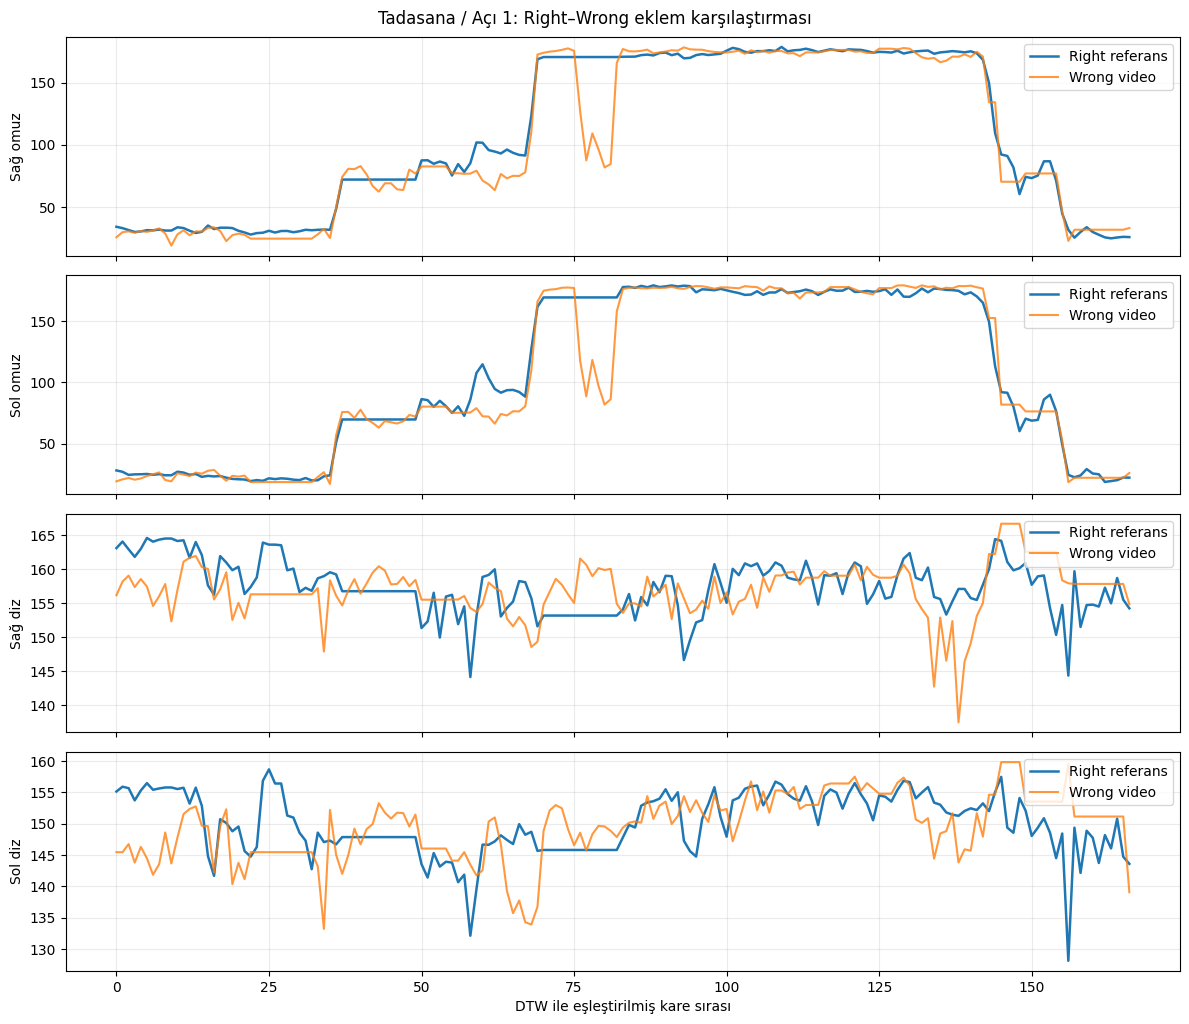

717

In [10]:
def cift_grafigi(ref_df,usr_df,path,detay,title,dosya):
    gorulebilir=[x for x in ['Sağ omuz','Sol omuz','Sağ diz','Sol diz','Sağ dirsek','Sol dirsek'] if x in detay.olcum.values]
    gorulebilir=gorulebilir[:4]
    if not gorulebilir: gorulebilir=detay.olcum.head(4).tolist()
    fig,axes=plt.subplots(len(gorulebilir),1,figsize=(12,max(3,len(gorulebilir)*2.6)),sharex=True)
    if len(gorulebilir)==1: axes=[axes]
    for ax,k in zip(axes,gorulebilir):
        ax.plot(np.arange(len(path)),ref_df[k].to_numpy()[path[:,0]],label='Right referans',lw=1.8)
        ax.plot(np.arange(len(path)),usr_df[k].to_numpy()[path[:,1]],label='Wrong video',lw=1.5,alpha=.8)
        ax.set_ylabel(k); ax.grid(alpha=.25)
        ax.legend(loc='upper right')
    axes[-1].set_xlabel('DTW ile eşleştirilmiş kare sırası')
    fig.suptitle(title);fig.tight_layout()
    fig.savefig(dosya,dpi=150,bbox_inches='tight')
    plt.show(); plt.close(fig)

cift_grafigi(ref_df,usr_df,path,detay,
             f'{sec.poz} / Açı {sec.aci}: Right–Wrong eklem karşılaştırması',
             SONUC_YOLU/'ornek_hareket_karsilastirmasi.png')
detay.to_csv(SONUC_YOLU/'ornek_olcumler.csv',index=False,encoding='utf-8-sig')
(SONUC_YOLU/'ornek_geri_bildirim.txt').write_text('\n'.join(genel_geri_bildirim(detay)),encoding='utf-8')

## 7b — Sapma anlarının kareleri (sunum için görsel kanıt)
Geri bildirimde geçen en önemli sapma anlarında Right (referans) ve Wrong karelerini yan yana gösterir. Metindeki iddiayı gözle doğrulamak için de kullan.

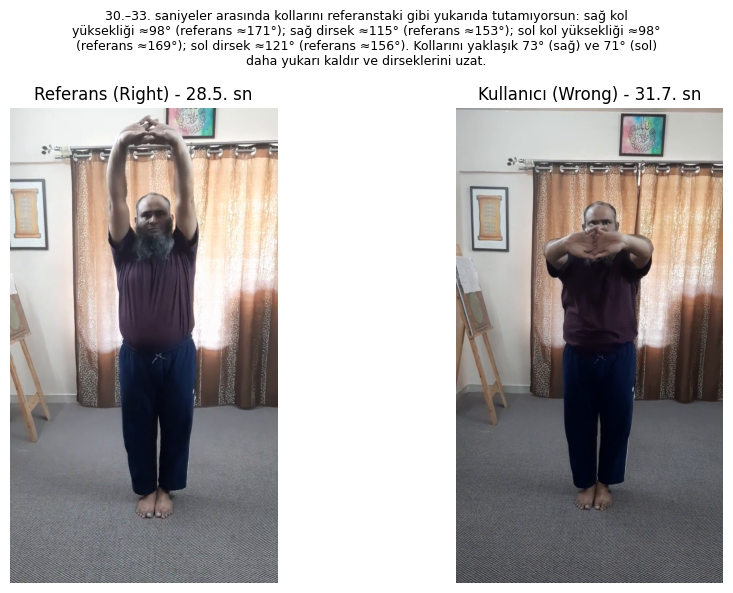

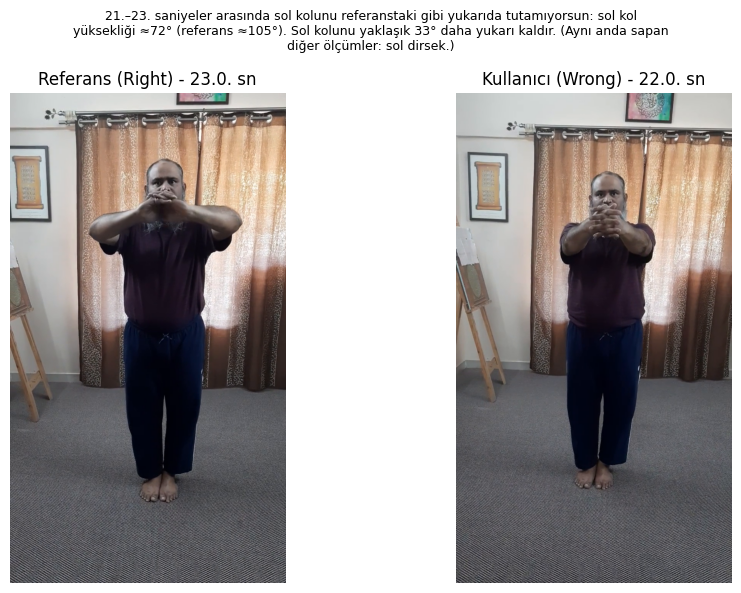

In [11]:
def video_kare(kayit, saniye):
    gecici = video_hazirla(kayit)
    cap = cv2.VideoCapture(str(gecici)); cap.set(cv2.CAP_PROP_POS_MSEC, float(saniye)*1000)
    ok, fr = cap.read(); cap.release()
    try: gecici.unlink(missing_ok=True)
    except OSError: pass
    return cv2.cvtColor(fr, cv2.COLOR_BGR2RGB) if ok else None

def sapma_karelerini_goster(detay, ref_kayit, usr_kayit, en_cok=3, onek='sapma'):
    for n, o in enumerate(detay.attrs.get('olaylar', [])[:en_cok], 1):
        sd = o['uyeler'][0]                                  # olayın en güçlü üyesi
        rt = (sd['seg_ref_t0'] + sd['seg_ref_t1']) / 2; ut = (sd['seg_user_t0'] + sd['seg_user_t1']) / 2
        a, b = video_kare(ref_kayit, rt), video_kare(usr_kayit, ut)
        if a is None or b is None: continue
        fig, ax = plt.subplots(1, 2, figsize=(10, 6))
        ax[0].imshow(a); ax[0].set_title(f'Referans (Right) - {rt:.1f}. sn'); ax[0].axis('off')
        ax[1].imshow(b); ax[1].set_title(f'Kullanıcı (Wrong) - {ut:.1f}. sn'); ax[1].axis('off')
        import textwrap
        fig.suptitle(textwrap.fill(_olay_metni(o, detay.attrs.get('dik', False)), 95), fontsize=9); fig.tight_layout()
        fig.savefig(SONUC_YOLU / f'{onek}_{n}.png', dpi=150, bbox_inches='tight'); plt.show(); plt.close(fig)

sapma_karelerini_goster(detay, ref_kayit, usr_kayit)

## 7c — Olumlu geri bildirim kontrolü
Right videosunu kendisiyle karşılaştırır. **Bu gerçek bir doğrulama değil**, sadece hareket toleranslar içindeyken sistemin motive edici mesaj ürettiğini gösterir.

In [12]:
d_ok, _, _, _ = olcumleri_karsilastir(ref_df, ref_df, aci=int(sec.aci), poz=sec.poz)
print(*genel_geri_bildirim(d_ok), sep='\n')

Hareketi doğru yaptın. Dirseklerin, kol kaldırma açın, kalça açıların ve dizlerin referans poza oldukça yakın, böyle devam et!


## 8 — BÜTÜN videoları analiz et
Başlangıçta **kapalıdır**. Tek çifti kontrol ettikten sonra `TUMUNU_CALISTIR = True` yaparak bütün eşleşen çiftleri çalıştır. Çalışma uzun sürerse baştan başlatabilirsin: her video analizinin CSV önbelleği saklanır.

In [13]:
TUMUNU_CALISTIR = True   # Tek çift doğruysa toplu çalıştır (önbellek sayesinde kesilirse devam eder).

if not TUMUNU_CALISTIR:
    print('Toplu analiz kapalı. Hazır olduğunda TUMUNU_CALISTIR = True yap.')
else:
    tum_detay=[]; tum_cift=[]; hatalar=[]
    for i,row in enumerate(CIFTLER.itertuples(index=False),1):
        print(f'[{i}/{len(CIFTLER)}] {row.poz} / Açı {row.aci}')
        try:
            rr=KATALOG.loc[KATALOG.video_id==row.right_id].iloc[0].to_dict()
            ww=KATALOG.loc[KATALOG.video_id==row.wrong_id].iloc[0].to_dict()
            R=video_analiz_et(rr); W=video_analiz_et(ww)
            det,yon,maliyet,kullan=olcumleri_karsilastir(R,W,aci=row.aci,poz=row.poz)
            det.insert(0,'poz',row.poz); det.insert(1,'aci',row.aci)
            det['geri_bildirim']=[turkce_oneri(k, det.attrs.get('dik', False)) for _,k in det.iterrows()]
            gb=genel_geri_bildirim(det)
            tum_detay.append(det)
            tum_cift.append(dict(poz=row.poz,aci=row.aci,
                                 right_gorunurluk=float(R.goruldu.mean()),
                                 wrong_gorunurluk=float(W.goruldu.mean()),
                                 dtw_maliyet=maliyet,
                                 medyan_tol_asim_orani=float(det.asim_orani.median()),
                                 sapma_olcum_sayisi=int((det.siddet_max>=SIDDET_ESIGI).sum()),
                                 olay_sayisi=len(det.attrs.get('olaylar',[])),
                                 tekrar_notu=(det.attrs.get('tekrar_notu') or ''),
                                 en_belirgin_olcum=(det.attrs['olaylar'][0]['uyeler'][0]['olcum'] if det.attrs.get('olaylar') else '-'),
                                 oneri=' | '.join(gb)))
            pd.concat(tum_detay,ignore_index=True).to_csv(SONUC_YOLU/'tum_eklem_sapmalari.csv',index=False,encoding='utf-8-sig')
            pd.DataFrame(tum_cift).to_csv(SONUC_YOLU/'tum_cift_ozetleri.csv',index=False,encoding='utf-8-sig')
        except Exception as e:
            hatalar.append(dict(poz=row.poz,aci=row.aci,hata=str(e)))
            print('  Analiz yapılamadı:',repr(e))
    if tum_cift:
        tablo=pd.DataFrame(tum_cift)
        print('Analiz edilen çift sayısı:',len(tablo))
        display(tablo.sort_values('sapma_olcum_sayisi',ascending=False))
        display(tablo.groupby('poz')[['medyan_tol_asim_orani','dtw_maliyet']].mean().round(3))
    if hatalar:
        pd.DataFrame(hatalar).to_csv(SONUC_YOLU/'analiz_hatalari.csv',index=False,encoding='utf-8-sig')
        print('Hata olan çift sayısı:',len(hatalar))
        display(pd.DataFrame(hatalar))

[1/40] Anantasana / Açı 1
[2/40] Anantasana / Açı 2
[3/40] Anantasana / Açı 3
[4/40] Anantasana / Açı 4
[5/40] Ardhakati Chakrasana / Açı 1
[6/40] Ardhakati Chakrasana / Açı 2
[7/40] Ardhakati Chakrasana / Açı 3
[8/40] Ardhakati Chakrasana / Açı 4
[9/40] Bhujangasana / Açı 1
[10/40] Bhujangasana / Açı 2
[11/40] Bhujangasana / Açı 3
[12/40] Bhujangasana / Açı 4
[13/40] Kati Chakrasana / Açı 1
[14/40] Kati Chakrasana / Açı 2
[15/40] Kati Chakrasana / Açı 3
[16/40] Kati Chakrasana / Açı 4
[17/40] Marjariasana / Açı 1
[18/40] Marjariasana / Açı 2
[19/40] Marjariasana / Açı 3
[20/40] Marjariasana / Açı 4
[21/40] Parvatasana / Açı 1
[22/40] Parvatasana / Açı 2
[23/40] Parvatasana / Açı 3
[24/40] Parvatasana / Açı 4
[25/40] Sarvangasana / Açı 1
[26/40] Sarvangasana / Açı 2
[27/40] Sarvangasana / Açı 3
[28/40] Sarvangasana / Açı 4
[29/40] Tadasana / Açı 1
[30/40] Tadasana / Açı 2
[31/40] Tadasana / Açı 3
[32/40] Tadasana / Açı 4
[33/40] Vajrasana / Açı 1
[34/40] Vajrasana / Açı 2
[35/40] Vajra

,poz,aci,right_gorunurluk,wrong_gorunurluk,dtw_maliyet,medyan_tol_asim_orani,sapma_olcum_sayisi,olay_sayisi,tekrar_notu,en_belirgin_olcum,oneri
36,Viparita Karani,1,0.979167,0.972028,3.894865,0.211429,13,11,Dikkat: bazı eklemlerde tekrar/geçiş sayısı fa...,Ayak açıklığı (oran),Hareketin referanstan belirgin biçimde ayrılıy...
32,Vajrasana,1,1.000000,1.000000,2.037219,0.212766,11,5,,Sağ diz,Hareketin referanstan belirgin biçimde ayrılıy...
20,Parvatasana,1,1.000000,1.000000,1.707020,0.082822,10,6,,Sağ omuz,Hareketin referanstan belirgin biçimde ayrılıy...
24,Sarvangasana,1,0.900709,0.831858,5.651347,0.522931,9,9,Dikkat: bazı eklemlerde tekrar/geçiş sayısı fa...,Gövde eğimi,Hareketin referanstan belirgin biçimde ayrılıy...
0,Anantasana,1,0.889381,0.830986,2.677010,0.427088,8,13,Dikkat: bazı eklemlerde tekrar/geçiş sayısı fa...,Sol diz,Hareketin referanstan belirgin biçimde ayrılıy...
1,Anantasana,2,1.000000,1.000000,1.641827,0.082192,8,4,Dikkat: bazı eklemlerde tekrar/geçiş sayısı fa...,Sol diz,Hareketin referanstan belirgin biçimde ayrılıy...
3,Anantasana,4,1.000000,1.000000,2.522790,0.042945,6,5,Dikkat: bazı eklemlerde tekrar/geçiş sayısı fa...,Sağ omuz,Hareketin referanstan belirgin biçimde ayrılıy...
28,Tadasana,1,1.000000,1.000000,1.286420,0.005988,6,2,,Sağ omuz,Hareketin referanstan belirgin biçimde ayrılıy...
16,Marjariasana,1,1.000000,1.000000,2.024563,0.086000,6,10,,Sağ kalça,Hareketin referanstan belirgin biçimde ayrılıy...
12,Kati Chakrasana,1,1.000000,1.000000,2.467544,0.082474,6,6,Dikkat: bazı eklemlerde tekrar/geçiş sayısı fa...,Sol omuz,Hareketin referanstan belirgin biçimde ayrılıy...


,medyan_tol_asim_orani,dtw_maliyet
poz,,
Anantasana,0.233,2.143
Ardhakati Chakrasana,0.119,2.141
Bhujangasana,0.061,1.822
Kati Chakrasana,0.057,1.788
Marjariasana,0.038,1.144
Parvatasana,0.065,1.548
Sarvangasana,0.170,2.201
Tadasana,0.016,1.281
Vajrasana,0.092,1.201


In [14]:
import html as _html
import ipywidgets as W
from IPython.display import display, clear_output, HTML

_pozlar = sorted(CIFTLER.poz.unique())
_poz = W.Dropdown(options=_pozlar, value=('Tadasana' if 'Tadasana' in _pozlar else _pozlar[0]), description='Hareket:')
_aci = W.Dropdown(options=[1, 2, 3, 4], value=1, description='Açı:')
_kare = W.Checkbox(value=True, description='Sapma karelerini göster', indent=False)
_btn = W.Button(description='Analiz et', button_style='primary', icon='play')
_out = W.Output()

def _calistir(_=None):
    with _out:
        clear_output(wait=True)
        s = CIFTLER[(CIFTLER.poz == _poz.value) & (CIFTLER.aci == _aci.value)]
        if s.empty:
            print('Bu hareket ve açı için eşleşen video çifti yok.')
            return
        s = s.iloc[0]
        print('Analiz ediliyor...')
        try:
            rk = KATALOG.loc[KATALOG.video_id == s.right_id].iloc[0].to_dict()
            uk = KATALOG.loc[KATALOG.video_id == s.wrong_id].iloc[0].to_dict()
            R = video_analiz_et(rk); U = video_analiz_et(uk)
            det, yol, maliyet, kullan = olcumleri_karsilastir(R, U, aci=int(s.aci), poz=s.poz)
        except Exception as e:
            clear_output(wait=True)
            print('Analiz yapılamadı:', e)
            return
        clear_output(wait=True)
        satirlar = genel_geri_bildirim(det)
        govde = ''.join(f'<p style="font-size:16px;line-height:1.5;margin:8px 0">{_html.escape(x)}</p>' for x in satirlar)
        display(HTML(f'<div style="font-family:sans-serif;max-width:900px;border:1px solid #ccc;border-radius:10px;padding:16px 20px;margin:10px 0">'
                     f'<div style="font-size:13px;color:#666">Geri bildirim · {_html.escape(str(s.poz))} · Açı {int(s.aci)} · {len(det)} ölçüm karşılaştırıldı</div>{govde}</div>'))
        if _kare.value:
            sapma_karelerini_goster(det, rk, uk, en_cok=1, onek=f'arayuz_{s.poz}_{int(s.aci)}')
        cift_grafigi(R, U, yol, det, f'{s.poz} / Açı {int(s.aci)}: referans ve kullanıcı açıları', SONUC_YOLU / 'arayuz_grafik.png')

_btn.on_click(_calistir)
display(W.VBox([
    W.HTML('<div style="font-family:sans-serif"><div style="font-size:22px;font-weight:600">PoseCoach</div>'
           '<div style="font-size:14px;color:#666">Hareketi ve kamera açısını seç; sistem referans videoyla karşılaştırıp geri bildirim verir.</div></div>'),
    W.HBox([_poz, _aci, _btn]), _kare, _out]))

In [15]:
import sys, subprocess, textwrap
try:
    import gradio as gr
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'])
    import gradio as gr

_WEB = SONUC_YOLU / 'web'
_WEB.mkdir(exist_ok=True)

def _kare_gorseli(det, rk, uk, ad):
    olaylar = det.attrs.get('olaylar', [])
    if not olaylar: return None
    sd = olaylar[0]['uyeler'][0]
    rt = (sd['seg_ref_t0'] + sd['seg_ref_t1']) / 2; ut = (sd['seg_user_t0'] + sd['seg_user_t1']) / 2
    a, b = video_kare(rk, rt), video_kare(uk, ut)
    if a is None or b is None: return None
    fig, ax = plt.subplots(1, 2, figsize=(10, 6))
    ax[0].imshow(a); ax[0].set_title(f'Referans - {rt:.1f}. sn'); ax[0].axis('off')
    ax[1].imshow(b); ax[1].set_title(f'Kullanıcı - {ut:.1f}. sn'); ax[1].axis('off')
    fig.tight_layout(); yol = _WEB / f'{ad}_kare.png'
    fig.savefig(yol, dpi=110, bbox_inches='tight'); plt.close(fig)
    return str(yol)

def _grafik(R, U, path, det, ad):
    sec_ = [x for x in ['Sağ omuz', 'Sol omuz', 'Sağ diz', 'Sol diz', 'Sağ dirsek', 'Sol dirsek'] if x in det.olcum.values][:4] or det.olcum.head(4).tolist()
    fig, axes = plt.subplots(len(sec_), 1, figsize=(11, max(3, len(sec_) * 2.4)), sharex=True)
    if len(sec_) == 1: axes = [axes]
    for ax, k in zip(axes, sec_):
        ax.plot(np.arange(len(path)), R[k].to_numpy()[path[:, 0]], label='Referans', lw=1.8)
        ax.plot(np.arange(len(path)), U[k].to_numpy()[path[:, 1]], label='Kullanıcı', lw=1.5, alpha=.8)
        ax.set_ylabel(k); ax.grid(alpha=.25); ax.legend(loc='upper right')
    axes[-1].set_xlabel('DTW ile eşleştirilmiş kare sırası')
    fig.tight_layout(); yol = _WEB / f'{ad}_grafik.png'
    fig.savefig(yol, dpi=110, bbox_inches='tight'); plt.close(fig)
    return str(yol)

def _analiz(rk, uk, aci, poz, ad):
    R = video_analiz_et(rk); U = video_analiz_et(uk)
    det, path, maliyet, kullan = olcumleri_karsilastir(R, U, aci=aci, poz=poz)
    metin = f'**{len(det)} / {len(FEATURES)} ölçüm karşılaştırıldı.**\n\n' + '\n\n'.join(genel_geri_bildirim(det))
    return metin, _kare_gorseli(det, rk, uk, ad), _grafik(R, U, path, det, ad)

def _veri_seti(poz, aci):
    try:
        s = CIFTLER[(CIFTLER.poz == poz) & (CIFTLER.aci == int(aci))]
        if s.empty: return 'Bu hareket ve açı için eşleşen video çifti yok.', None, None
        s = s.iloc[0]
        rk = KATALOG.loc[KATALOG.video_id == s.right_id].iloc[0].to_dict()
        uk = KATALOG.loc[KATALOG.video_id == s.wrong_id].iloc[0].to_dict()
        return _analiz(rk, uk, int(s.aci), s.poz, f'{s.poz}_{int(s.aci)}'.replace(' ', '_'))
    except Exception as e:
        return f'Analiz yapılamadı: {e}', None, None

def _yukleme(ref_video, usr_video, poz, yandan):
    if not ref_video or not usr_video: return 'İki videoyu da yükle: referans ve kullanıcı.', None, None
    try:
        rk = dict(kaynak=str(ref_video), zip_uyesi='', tip='video'); uk = dict(kaynak=str(usr_video), zip_uyesi='', tip='video')
        return _analiz(rk, uk, 2 if yandan else 1, None if poz == 'Diğer' else poz, 'yukleme')
    except Exception as e:
        return f'Analiz yapılamadı: {e}', None, None

_pozlar = sorted(CIFTLER.poz.unique())
with gr.Blocks(title='PoseCoach') as demo:
    gr.Markdown('# PoseCoach\nYoga hareketini referans videoyla karşılaştırır; hatalı eklemi, zamanını, kaç derece olduğunu ve nasıl düzeltileceğini söyler.')
    with gr.Tab('Veri setinden seç'):
        with gr.Row():
            d_poz = gr.Dropdown(choices=_pozlar, value=('Tadasana' if 'Tadasana' in _pozlar else _pozlar[0]), label='Hareket')
            d_aci = gr.Dropdown(choices=[1, 2, 3, 4], value=1, label='Kamera açısı')
            b1 = gr.Button('Analiz et', variant='primary')
        o1 = gr.Markdown(label='Geri bildirim')
        with gr.Row():
            i1 = gr.Image(label='Sapma anı: referans ve kullanıcı', type='filepath')
            g1 = gr.Image(label='Hizalanmış açı eğrileri', type='filepath')
        b1.click(_veri_seti, [d_poz, d_aci], [o1, i1, g1])
    with gr.Tab('Kendi videonu yükle'):
        gr.Markdown('İki video aynı hareketi aynı kamera açısından göstermeli. İlk analiz video başına bir iki dakika sürebilir; en çok ilk 120 saniye işlenir.')
        with gr.Row():
            v_ref = gr.Video(label='Referans video (doğru yapılış)')
            v_usr = gr.Video(label='Kullanıcı videosu')
        with gr.Row():
            u_poz = gr.Dropdown(choices=_pozlar + ['Diğer'], value='Diğer', label='Hareket')
            u_yan = gr.Checkbox(label='Yandan çekim', value=False)
            b2 = gr.Button('Analiz et', variant='primary')
        o2 = gr.Markdown(label='Geri bildirim')
        with gr.Row():
            i2 = gr.Image(label='Sapma anı: referans ve kullanıcı', type='filepath')
            g2 = gr.Image(label='Hizalanmış açı eğrileri', type='filepath')
        b2.click(_yukleme, [v_ref, v_usr, u_poz, u_yan], [o2, i2, g2])

demo.launch(share=True, inline=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d488bc538ef1ef6653.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 9 — Raporlama notları ve kaynaklar

**Yöntem:** Right/ Wrong video eşleşmesi (aynı hareket + aynı kamera yönü) → MediaPipe Pose Landmarker ile 33 landmark → 3B (world landmark) eklem açıları ve görüntü düzleminde normalize ölçümler → DTW ile hareket anlarının eşleştirilmesi → açı farkları, 90. yüzdelik ve tolerans aşım oranı → Türkçe düzeltme önerisi.

**Kendi katkımız:** Sağ/sol eklem geometrisi, referans bazlı açı zaman serisi karşılaştırması, DTW hizalama ve eklem bazlı kural tabanlı geri bildirim. Tolerans değerleri **deneysel başlangıç eşikleri** olup bilimsel olarak kalibre edilmiş klinik normlar değildir.

**Son iyileştirmeler:** (1) Eklem açıları MediaPipe `pose_world_landmarks` (3B, metre) ile hesaplanır; kameraya doğru uzanan kollardaki 2B perspektif kısalması azalır (gövde eğimi, omuz hizası, bilek yüksekliği ve ayak açıklığı görüntü düzleminde kalır). (2) Aynı anda sapan ölçümler tek olayda birleştirilir; referansın hızlı değiştiği geçiş evrelerindeki sapmalar düşük puanlanır; yalnızca toleransın ≥1,5 katı sapmalar raporlanır.

**Veri ön işleme:** Orijinal arşivden yalnızca videolar ayrıldı; bazı kamera açısı etiketleri düzeltilerek eşleştirildi. Rapor için hangi dosyaların yeniden adlandırıldığının kaydı korunmalıdır.

**Önemli sınırlılıklar:** Tek Right video evrensel doğru poz anlamına gelmez; kamera perspektifi görüntü düzlemindeki ölçümleri (gövde eğimi, omuz hizası) etkiler; 3B açılar world landmark gürültüsünden etkilenir; düşük görünürlük bazı ölçümleri geçersiz kılar; DTW sıra dışı tekrarları eşleme sırasında kısmen maskeleyebilir. Tadasana için önceki defterde ayrıca erken kol indirme olayı ölçülmüştü; burada tüm hareketler için ortak algoritma kullanılıyor.

**Kaynaklar:** Google MediaPipe Pose Landmarker Python resmi belgeleri: https://developers.google.com/edge/mediapipe/solutions/vision/pose_landmarker/python ; DTW, SciPy cdist ile hesaplanan uzaklık matrisi üzerinde elle yazılmış dinamik programlama olarak uygulandı; Yoga for All veri seti: https://doi.org/10.17632/jc4mmnvcdk.1 .
**Ek doğrulama:** v10.1 için yalnızca sözdizimi ve hedefli sentetik testler yapılmıştır. Gerçek veri seti üzerindeki bütün sonuçların yeni defter çalıştırılarak doğrulanması gerekir.
